In [1]:
import sys
sys.path.insert(1, '/home/santolam/MyPythonLibrary/MAR-RECAP/libmar/')
import climbasis as climb
from climbasis import *
import domain as dom
import myplot
import numpy.ma as ma
from myplot import *
import obsinfo as obs
from obsinfo import *


In [2]:
domain='GRc';spin='spin2';var='T';units='°C';domainM='GRq'

nx=10;ny=10
iyr=1980
fyr=2020

In [3]:
sourceData=f'/bettik/PROJECTS/pr-regional-climate/santolam/MARout_post/{domainM}/spin2/work/monthly/'


In [4]:
ds_grM= xr.open_dataset('/home/santolam/NST.2000.01.01.00.GRc.nc')
LONS=ds_grM.LON[ny:-ny,nx:-nx].values
LATS=ds_grM.LAT[ny:-ny,nx:-nx].values
dsSH=ds_grM.SH[ny:-ny,nx:-nx]
dsICE=ds_grM.ICE[ny:-ny,nx:-nx]
latS=LATS.min(); latN=LATS.max()
lonW=LONS.min(); lonE=LONS.max()

field0_SH=dsSH;
field0_ICE=dsICE;

In [5]:
#!ls /bettik/PROJECTS/pr-regional-climate/santolam/MARout/GRp/spin2/work/monthly/TT*

In [6]:
def seasonal_mean(ds, months):
    """Return seasonal mean for specified list of months."""
    return ds.where(ds['time.month'].isin(months), drop=True).groupby('time.year').mean('time')

In [7]:
#Nepal (Central Himalaya) [‘DJFM’, ‘AM’, ‘JJAS’, ‘ON’]

In [8]:
#season="DJFM"
#rmons=[12,1,2,3]
season="AM"
rmons=[4,5]

In [9]:
##ax0
ds0_raw= xr.open_dataset(sourceData+
                           'TTZ_mon_MARv3.14_ER5_spin2_'+domainM+'_1980-2024.nc')['TTZ'][:,0,:,:] ## montlhy mean
ds0 = ds0_raw.rename({'TIME': 'time'})
field0=ds0[:,ny:-ny,nx:-nx].sel(time=slice(str(iyr),str(fyr)))

#annual_mean_f0 = field0.resample(time='YS').mean()
#clim_f0 = annual_mean_f0.mean(dim='time')
seasonal_mean_f0=seasonal_mean(field0, rmons)
clim_f0=seasonal_mean_f0.mean('year')

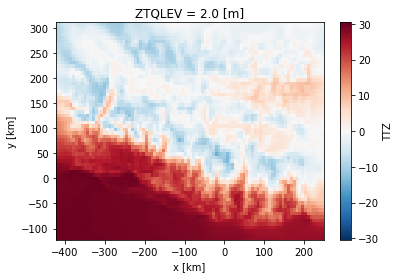

In [10]:
clim_f0.plot()

In [11]:
##ax1

ds1_raw = xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/cru/'
                      +'tmp_cru405_mon_19010116-20201216_05x05_GLOB.nc')['tmp']

field1 =ds1_raw.sel(time=slice(str(iyr),str(fyr))).sel(lat=slice(latS,latN),lon=slice(lonW,lonE))

seasonal_mean_f1=seasonal_mean(field1, rmons)
clim_f1=seasonal_mean_f1.mean('year')

ds1_SH=xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/gmted/'
                       +'gmted_on_cru_hma_grid.nc')['elevation']
#ds5_SH=dom.reversing_lat(ds5_SH_raw)
field1_SH=ds1_SH.sel(lat=slice(latS,latN),lon=slice(lonW,lonE))


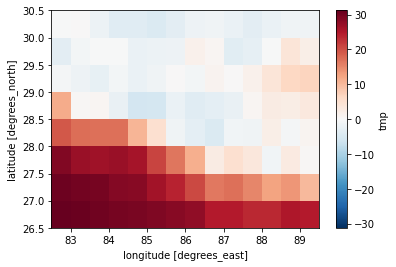

In [12]:
clim_f1.plot()

In [13]:
##ax2
ds2_raw=xr.open_dataset(f'/bettik/PROJECTS/pr-regional-climate/santolam/MARout_coarser/'+
                            f'TTZ_mon_MARv3.14_ER5_spin2_{domainM}_1980-2024_cru05x05.nc')['TTZ'][:,0,:,:]
mask = np.isfinite(ds2_raw).any(dim='TIME')  # problem of global, all grid nan
ds2_raw_mask= ds2_raw.where(mask, drop=True)

ds2= ds2_raw_mask.rename({'TIME': 'time','x':'longitude','y':'latitude'})

field2=ds2.sel(time=slice(str(iyr), str(fyr))).sel(latitude=slice(latS,latN),longitude=slice(lonW,lonE))

#annual_mean_f2 = field2.resample(time='YS').mean()
#clim_f2= annual_mean_f2.mean(dim='time')
seasonal_mean_f2=seasonal_mean(field2, rmons)
clim_f2=seasonal_mean_f2.mean('year')

bias_f2=clim_f2.values-clim_f1.values


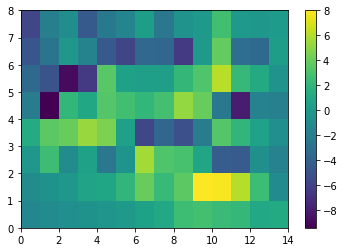

In [14]:
plt.pcolormesh(bias_f2)
plt.colorbar()

In [15]:
###ax3

ds_RF_raw=xr.open_dataset(f'/bettik/PROJECTS/pr-regional-climate/santolam/MARout_post/{domainM}/spin2/work/monthly/'
                          +'RF_mon_MARv3.14_ER5_spin2_'+domainM+'_1980-2024.nc')['RF']
ds_RF = ds_RF_raw.rename({'TIME': 'time'})
###
ds_SF_raw=xr.open_dataset(f'/bettik/PROJECTS/pr-regional-climate/santolam/MARout_post/{domainM}/spin2/work/monthly/'
                        +'SF_mon_MARv3.14_ER5_spin2_'+domainM+'_1980-2024.nc')['SF']
ds_SF = ds_SF_raw.rename({'TIME': 'time'})

ds3=ds_RF+ds_SF

field3=ds3[:,ny:-ny,nx:-nx].sel(time=slice(str(iyr), str(fyr)))

#annual_mean_f3 = field3.resample(time='YS').mean()
#clim_f3 = annual_mean_f3.mean(dim='time')

seasonal_mean_f3=seasonal_mean(field3, rmons)
clim_f3=seasonal_mean_f3.mean('year')

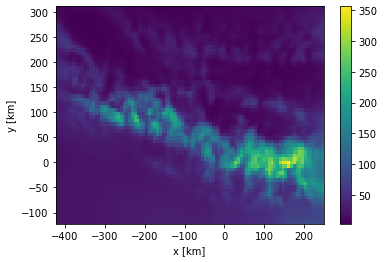

In [16]:
clim_f3.plot()

In [17]:
#ax4
ds4 = xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/aphro/monthly/'
                      +'APHRO_mon_MA_025deg_V1101_EXR1.1951-2015.nc',decode_times=False)['precip']
start_date = pd.Timestamp('1951-01-01')
# Create new time index
nmonths = ds4.time.size
time_new = pd.date_range(start=start_date, periods=nmonths, freq='MS')  # 'MS' = Month Start
# Replace time in dataset
ds4['time'] = time_new
ds4=dom.reversing_lat(ds4)
ds4=ds4.rename({'latitude':'lat','longitude':'lon'})
field4_mm_day=ds4.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))
field4_mm_day=field4_mm_day.sel(time=slice(str(iyr),str(fyr)))

# Convert mm/day to mm/month
days_in_month = field4_mm_day['time'].dt.days_in_month
field4= field4_mm_day * days_in_month

#annual_mean_f4= field4.resample(time='YS').mean()
#clim_f4 = annual_mean_f4.mean(dim='time')
seasonal_mean_f4=seasonal_mean(field4, rmons)
clim_f4=seasonal_mean_f4.mean('year')

ds4_SH_raw=xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/gmted/'+'gmted_on_aphro.nc')['elevation']
ds4_SH=ds4_SH_raw.rename({'latitude':'lat','longitude':'lon'})
ds4_SH=dom.reversing_lat(ds4_SH)
field4_SH=ds4_SH.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))



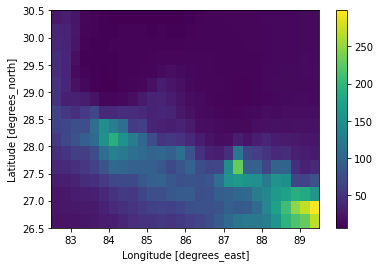

In [18]:
clim_f4.plot()

In [19]:
##ax5
ds_RF_raw=xr.open_dataset(f'/bettik/PROJECTS/pr-regional-climate/santolam/MARout_coarser/'+
                            f'RF_mon_MARv3.14_ER5_spin2_{domainM}_1980-2024_aphro025x025.nc')['RF']
mask = np.isfinite(ds_RF_raw).any(dim='TIME')  # cells valid at least once
ds_RF = ds_RF_raw.where(mask, drop=True)
ds_SF_raw=xr.open_dataset(f'/bettik/PROJECTS/pr-regional-climate/santolam/MARout_coarser/'+
                            f'SF_mon_MARv3.14_ER5_spin2_'+domainM+'_1980-2024_aphro025x025.nc')['SF']
maskSF = np.isfinite(ds_SF_raw).any(dim='TIME')  # cells valid at least once
ds_SF = ds_SF_raw.where(maskSF, drop=True)
ds_TF=ds_RF+ds_SF

ds5 = ds_TF.rename({'TIME': 'time','x':'longitude','y':'latitude'})
field5=ds5.sel(time=slice(str(iyr), str(fyr))).sel(latitude=slice(latS,latN),longitude=slice(lonW,lonE))

field5=dom.reversing_lat(field5)

#annual_mean_f5 = field5.resample(time='YS').mean()
#clim_f5=annual_mean_f5.mean(dim='time')
seasonal_mean_f5=seasonal_mean(field5, rmons)
clim_f5=seasonal_mean_f5.mean('year')

bias_f5=clim_f5.values-clim_f4.values


In [20]:
bias_f5.shape

(16, 28)

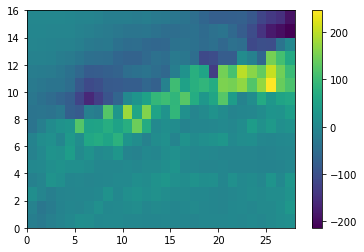

In [21]:
plt.pcolormesh(bias_f5)
plt.colorbar()

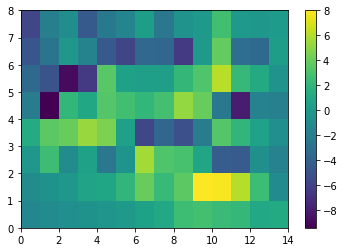

In [22]:
plt.pcolormesh(bias_f2)
plt.colorbar()

In [23]:
np.max(bias_f2)

8.0006275e+00

In [24]:
clevs3 = np.arange(5, 100, 10)
cmap_mod3 = plt.get_cmap('Blues', len(clevs3) + 1)
colors3 = [cmap_mod3(j) for j in range(cmap_mod3.N)]
colors3[0] = (1, 1, 1, 1)  # white for 0
cmap3 = mcolors.ListedColormap(colors3)
norm3 = mcolors.BoundaryNorm(clevs3, cmap3.N, extend='both')



In [25]:
plotList=[
clim_f0,clim_f1,bias_f2,
clim_f3,clim_f4,bias_f5,
#clim_f6,clim_f7,bias_f8,
]

clevsList=[
np.arange(-30,33,3),np.arange(-30,33,3),np.arange(-14, 16, 2),
clevs3, clevs3,np.arange(-50, 55, 5)#,
#clevs6,clevs6,np.arange(-50, 55, 5)
]
cmapList=[
plt.get_cmap('RdYlBu_r'),plt.get_cmap('RdYlBu_r'),plt.get_cmap('bwr'),
cmap3 ,cmap3 ,plt.get_cmap('BrBG')#,
#cmap6 ,cmap6 ,  plt.get_cmap('bwr_r')  
]


norm0=mcolors.BoundaryNorm(clevsList[0], cmapList[0].N, extend='both')
norm2=mcolors.BoundaryNorm(clevsList[2], cmapList[2].N, extend='both')
norm5=mcolors.BoundaryNorm(clevsList[5], cmapList[5].N, extend='both')
#norm8=mcolors.BoundaryNorm(clevsList[8], cmapList[8].N, extend='both')

normList=[
    norm0,norm0,norm2,
    norm3,norm3,norm5,
#    norm6,norm6,norm8
]


In [ ]:
fig, axs = plt.subplots(
    2, 3, figsize=(28, 24),
    subplot_kw={'projection': ccrs.PlateCarree()}
)

ax0 = axs[0,0];ax1 = axs[0,1];ax2 = axs[0,2]

ax3 = axs[1,0];ax4 = axs[1,1];ax5 = axs[1,2]

#ax6 = axs[2,0];ax7 = axs[2,1];ax8 = axs[2,2]

##Temperature
lons0,lats0=LONS,LATS
im0 = ax0.pcolormesh(lons0, lats0, clim_f0,
                     transform=ccrs.PlateCarree(),
                     cmap=cmapList[0], norm=normList[0], shading='auto')
ax0.add_feature(cfeature.COASTLINE)
ax0.add_feature(cfeature.BORDERS, linestyle=':')
#ax0.set_title("(a1) Temperature – Model", fontsize=18)
SH0 = ax0.contour(lons0, lats0, field0_SH,
                     levels=[1000,2000,3000,4000,5000,6000,7000],
                     colors="k", linewidths=0.5, alpha=0.7,
                     transform=ccrs.PlateCarree())
ax0.clabel(SH0, inline=True, fontsize=10, fmt="%d")
# Obs
lons1,lats1=clim_f1.lon,clim_f1.lat
im1 = ax1.pcolormesh(lons1, lats1, clim_f1,
                     transform=ccrs.PlateCarree(),
                     cmap=cmapList[1], norm=normList[1], shading='auto')
ax1.add_feature(cfeature.COASTLINE)
ax1.add_feature(cfeature.BORDERS, linestyle=':')
SH1 = ax1.contour(lons1, lats1, field1_SH,
                     levels=[1000,2000,3000,4000,5000,6000,7000],
                     colors="k", linewidths=0.5, alpha=0.7,
                     transform=ccrs.PlateCarree())
ax1.clabel(SH1, inline=True, fontsize=10, fmt="%d")
#ax1.set_title("(a2) Temperature – Obs", fontsize=18)

# Bias
im2 = ax2.pcolormesh(lons1, lats1, bias_f2,
                     transform=ccrs.PlateCarree(),
                     cmap=cmapList[2], norm=normList[2], shading='auto')
ax2.add_feature(cfeature.COASTLINE)
ax2.add_feature(cfeature.BORDERS, linestyle=':')
SH1 = ax2.contour(lons1, lats1, field1_SH,
                     levels=[1000,2000,3000,4000,5000,6000,7000],
                     colors="k", linewidths=0.5, alpha=0.7,
                     transform=ccrs.PlateCarree())
ax2.clabel(SH1, inline=True, fontsize=10, fmt="%d")

#ax2.set_title("(a3) Temperature – Bias", fontsize=18)

# -----------------------------------------
#  PRECIPITATION 
# -----------------------------------------

# Model
im3 = ax3.pcolormesh(lons0, lats0, clim_f3,
                     transform=ccrs.PlateCarree(),
                     cmap=cmapList[3], norm=normList[3], shading='auto')
ax3.add_feature(cfeature.COASTLINE)
ax3.add_feature(cfeature.BORDERS, linestyle=':')
#ax3.set_title("(b1) Precip – Model", fontsize=18)
SH0 = ax3.contour(lons0, lats0, field0_SH,
                     levels=[1000,2000,3000,4000,5000,6000,7000],
                     colors="k", linewidths=0.5, alpha=0.7,
                     transform=ccrs.PlateCarree())
ax3.clabel(SH0, inline=True, fontsize=10, fmt="%d")
# Obs
lons4,lats4=clim_f4.lon,clim_f4.lat
im4 = ax4.pcolormesh(lons4, lats4, clim_f4,
                     transform=ccrs.PlateCarree(),
                     cmap=cmapList[4], norm=normList[4], shading='auto')
ax4.add_feature(cfeature.COASTLINE)
ax4.add_feature(cfeature.BORDERS, linestyle=':')
SH4 = ax4.contour(lons4, lats4, field4_SH,
                     levels=[1000,2000,3000,4000,5000,6000,7000],
                     colors="k", linewidths=0.5, alpha=0.7,
                     transform=ccrs.PlateCarree())
ax4.clabel(SH4, inline=True, fontsize=10, fmt="%d")

#ax4.set_title("(b2) Precip – Obs", fontsize=18)

# Bias
im5 = ax5.pcolormesh(lons4, lats4, bias_f5,
                     transform=ccrs.PlateCarree(),
                     cmap=cmapList[5], norm=normList[5], shading='auto')
ax5.add_feature(cfeature.COASTLINE)
ax5.add_feature(cfeature.BORDERS, linestyle=':')
SH5 = ax5.contour(lons4, lats4, field4_SH,
                     levels=[1000,2000,3000,4000,5000,6000,7000],
                     colors="k", linewidths=0.5, alpha=0.7,
                     transform=ccrs.PlateCarree())
ax5.clabel(SH5, inline=True, fontsize=10, fmt="%d")

#ax5.set_title("(b3) Precip – Bias", fontsize=18)


# Zero-isoline for temperature row
ax0.contour(lons0, lats0, clim_f0, levels=[0], colors="blue", linewidths=2)
ax1.contour(lons1, lats1, clim_f1, levels=[0], colors="blue", linewidths=2)
#ax2.contour(lons, lats, clim_f0, levels=[0], colors="blue", linewidths=2)


# -----------------------------------------
#  GRIDLINES 
# -----------------------------------------
axs_f = axs.flatten()

for i, ax in enumerate(axs_f):

    gl = ax.gridlines(
        crs=ccrs.PlateCarree(),
        draw_labels=True,
        linewidth=1,
        color="gray",
        alpha=0.3,
        linestyle=":"
    )

    gl.xlabel_style = {"size": 16}
    gl.ylabel_style = {"size": 16}

    # Remove labels on all sides first
    gl.top_labels = False
    gl.bottom_labels = False
    gl.left_labels = False
    gl.right_labels = False

    # Apply desired labeling logic
    if i in [0, 3, 6]:           # left column
        gl.top_labels = True
        gl.bottom_labels = True
        gl.left_labels = True

    elif i in [1, 4, 7]:         # middle column
        gl.top_labels = True
        gl.bottom_labels = True

    elif i in [2, 5, 8]:         # right column
        gl.top_labels = True
        gl.bottom_labels = True
        gl.right_labels = True
        
###
## Letters
###
letterList = ["a)", "b)", "c)", "d)", "e)", "f)", "g)", "h)", "i)"]

for i, ax in enumerate(axs.flatten()):
    ax.text(
        0.02, 0.98,            # position inside axes (left, top)
        letterList[i],
        transform=ax.transAxes,
        fontsize=24,
        fontweight='bold',
        va='top',
        ha='left',
        bbox=dict(facecolor='white', edgecolor='none', alpha=0.9, pad=2)
    )
    
for ax in axs.flatten():
    ax.set_aspect(1.4)
    
# -----------------------------------------
# COLORBARS
# -----------------------------------------
cbar_loc_ax0= fig.add_axes([0.20, 0.5, 0.3, 0.02]) ##[x0, y0, width, height]
cbar_ax0 = fig.colorbar(im0, cax=cbar_loc_ax0, orientation="horizontal")
cbar_ax0.set_label("T [°C]", fontsize=18)
cbar_ax0.ax.tick_params(labelsize=18)

cbar_loc_ax2= fig.add_axes([0.65, 0.5, 0.3, 0.02])
cbar_ax2 = fig.colorbar(im2, cax=cbar_loc_ax2, orientation="horizontal")
cbar_ax2.set_label("$\Delta$T [°C]", fontsize=18)
cbar_ax2.ax.tick_params(labelsize=18)

cbar_loc_ax3= fig.add_axes([0.20, 0.12, 0.3, 0.02]) ##[x0, y0, width, height]
cbar_ax3 = fig.colorbar(im3, cax=cbar_loc_ax3, orientation="horizontal")
cbar_ax3.set_label(label="PRE [mm/month]",fontsize=18)
cbar_ax3.ax.tick_params(labelsize=18)

cbar_loc_ax5= fig.add_axes([0.65, 0.12, 0.3, 0.02])
cbar_ax5 = fig.colorbar(im5, cax=cbar_loc_ax5, orientation="horizontal")
cbar_ax5.set_label(label="$\Delta$ PRE[mm/month]",fontsize=18)
cbar_ax5.ax.tick_params(labelsize=18)
# -----------------------------------------
# Layout + Save
# -----------------------------------------
plt.subplots_adjust(left=0.03, right=0.95, top=0.85, bottom=0.15,
                    wspace=0.1, hspace=0.25)
plotname=f"support_FIG3_clim_bias_{season}_nepal.png"
fig.suptitle(plotname, fontsize=30,y=0.88)

plotsDir = "/home/santolam/RECAP/figures/paper_on_validation_RECAP/"

plt.savefig(plotsDir+plotname, dpi=300, bbox_inches="tight")

plt.show()
